# A static energy budget for atmospheric escape

We use a deliberately idealized planet to inspect an energy-limited mass-loss calculation. The planet has a fixed mass of five Earth masses. We vary its radius from one to three Earth radii, heating efficiency from 0.05 to 0.3, and incident X-ray and extreme-ultraviolet (XUV) flux from 1 to $10^4$ W/m$^2$.

The absorbed power is $\eta\pi R_{\rm abs}^{2}F_{\rm XUV}$ and the binding energy per unit mass is $GM_pK/R_p$. Dividing them gives $\dot M=\eta\pi R_{\rm abs}^{2}F_{\rm XUV}R_p/(GM_pK)$. Here we set $R_{\rm abs}=R_p$ and $K=1$. The example calls TDpy's unit-aware helper through the repository's callable script.

These are assumed inputs, not observed planets. Erkaev et al. (2007), *A&A*, 472, 329, DOI `10.1051/0004-6361:20066929`, discuss the energy-limited approximation and the Roche correction. No atmospheric evolution or observational population test is performed.

,planet_mass_earth,planet_radius_earth,xuv_flux_w_m2,efficiency,absorption_radius_ratio,roche_factor,mass_loss_g_s
0,5.0,1.0,1.000000,0.05,1.0,1.0,2.044966e+07
1,5.0,1.0,1.123655,0.05,1.0,1.0,2.297836e+07
2,5.0,1.0,1.262600,0.05,1.0,1.0,2.581974e+07
3,5.0,1.0,1.418727,0.05,1.0,1.0,2.901248e+07
4,5.0,1.0,1.594159,0.05,1.0,1.0,3.260001e+07


minimum_rate_g_s  maximum_rate_g_s
planet_radius_earth efficiency                                    
1.0                 0.05            2.044966e+07      2.044966e+11
                    0.10            4.089932e+07      4.089932e+11
                    0.30            1.226980e+08      1.226980e+12
2.0                 0.05            1.635973e+08      1.635973e+12
                    0.10            3.271946e+08      3.271946e+12
                    0.30            9.815837e+08      9.815837e+12
3.0                 0.05            5.521408e+08      5.521408e+12
                    0.10            1.104282e+09      1.104282e+13
                    0.30            3.312845e+09      3.312845e+13

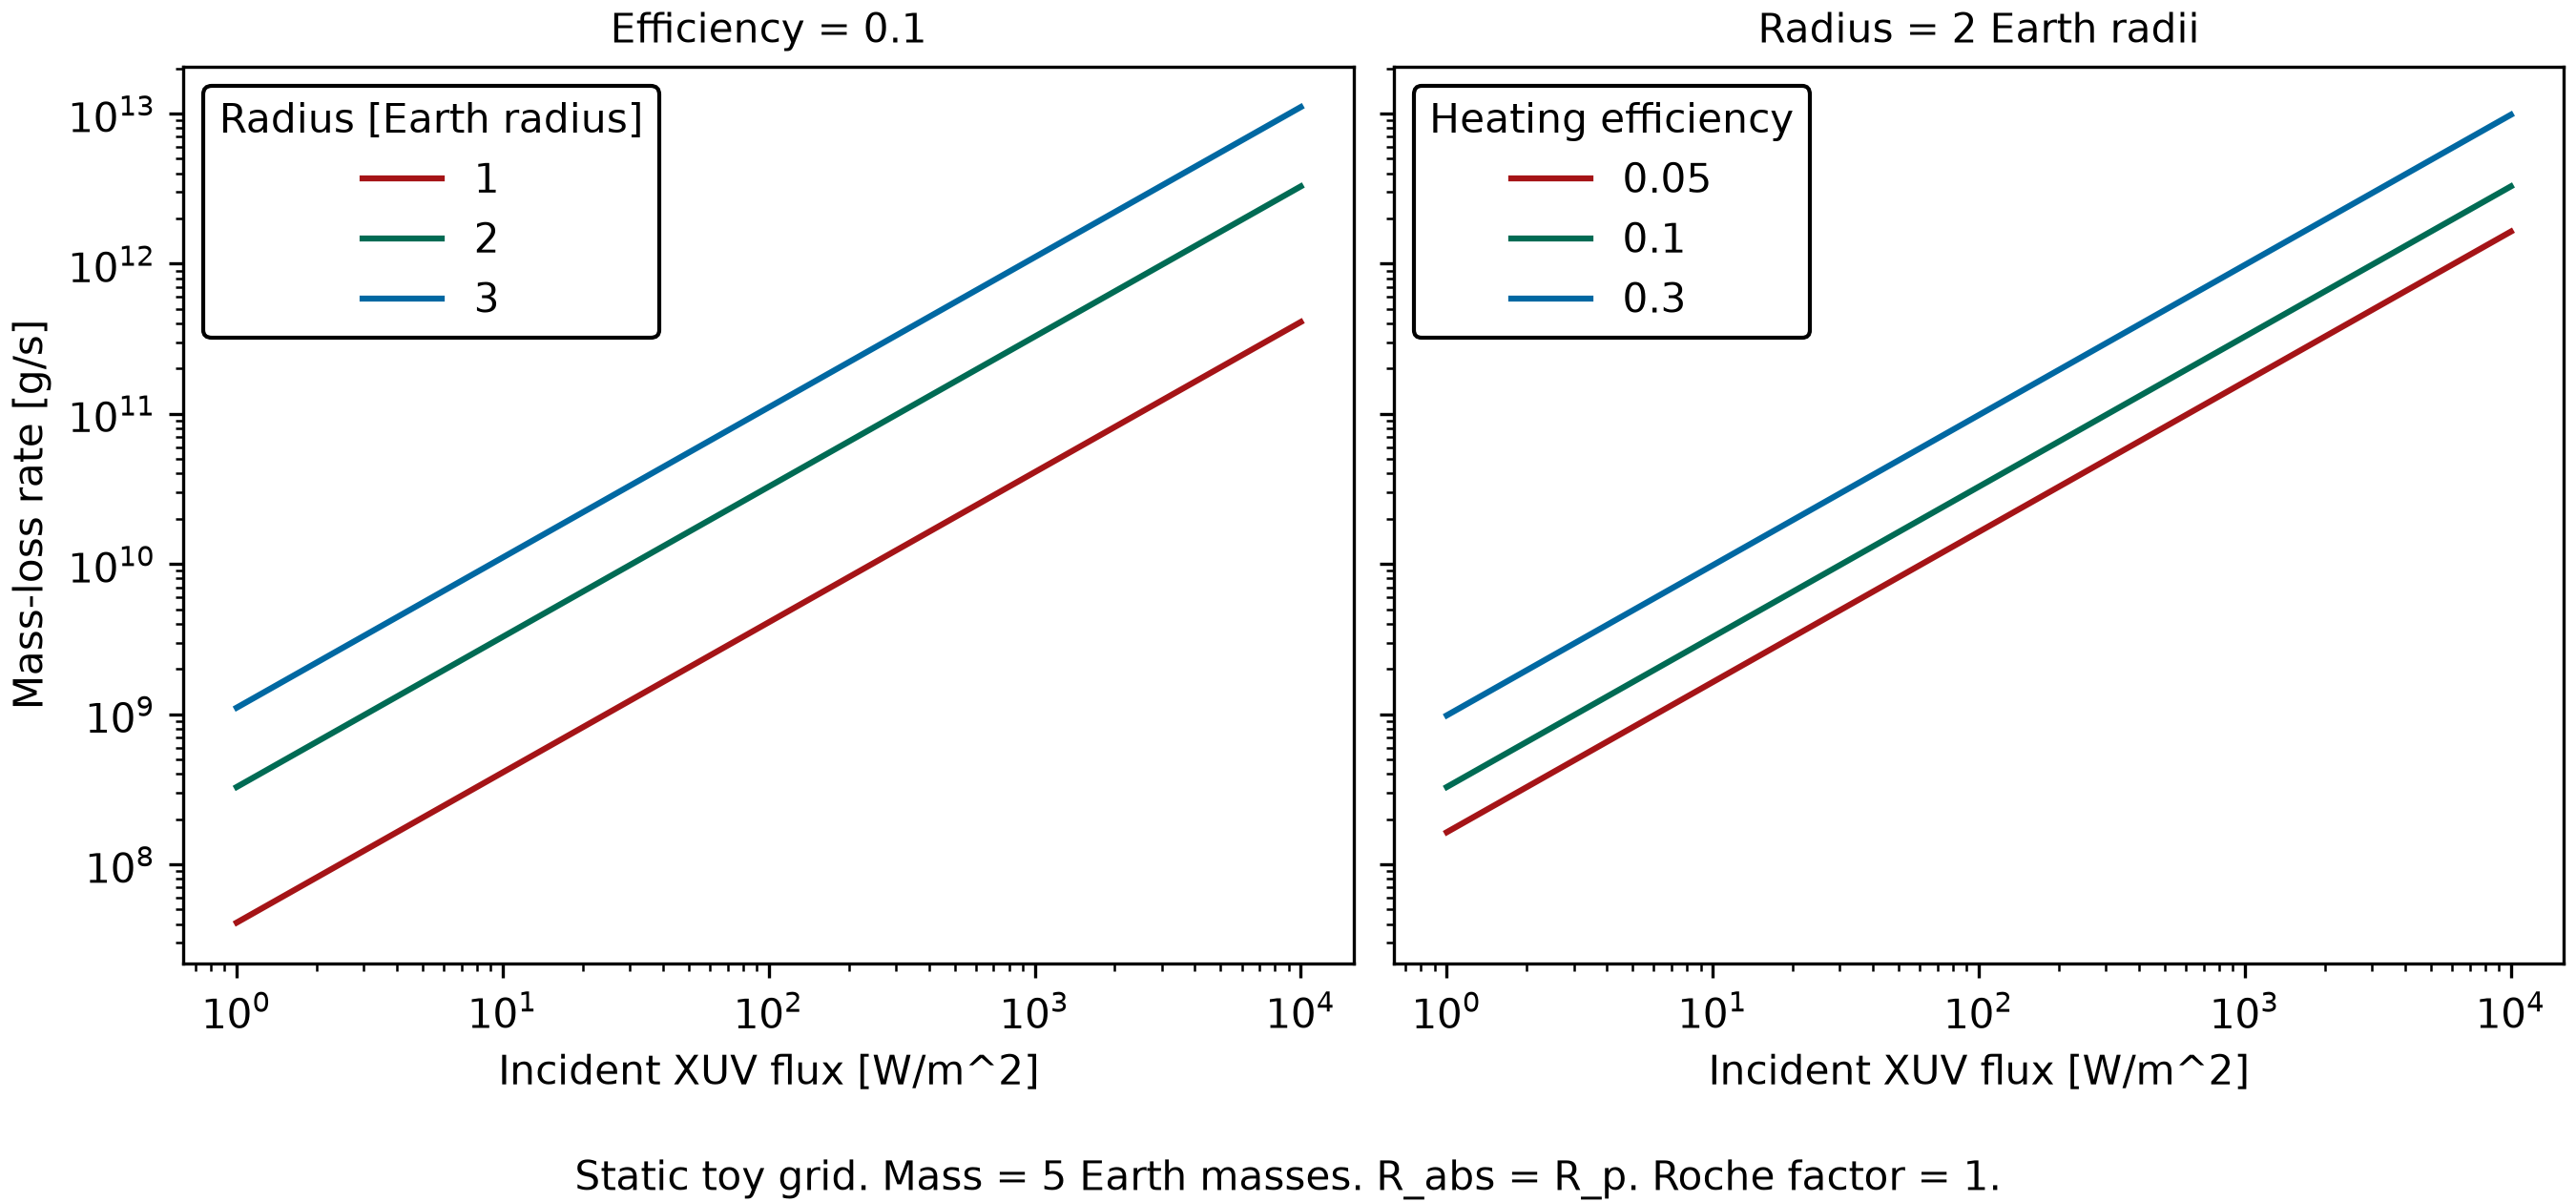

In [1]:
from pathlib import Path
import runpy

import matplotlib
matplotlib.use('Agg')
from IPython.display import Image, display

example_directory = next((candidate for candidate in (Path('.'), Path('examples'))
                          if (candidate / 'energy_limited_escape.ipynb').is_file()), None)
if example_directory is None:
    raise ValueError('Run from the repository root or its examples directory')
script_path = example_directory / '..' / 'scripts' / 'energy_limited_escape.py'
workflow = runpy.run_path(str(script_path))
result = workflow['run_example'](example_directory / 'visuals', write_bokeh=True)
table = result['table']
display(table.head())
display(table.groupby(['planet_radius_earth', 'efficiency']).agg(
    minimum_rate_g_s=('mass_loss_g_s', 'min'), maximum_rate_g_s=('mass_loss_g_s', 'max'),
))
display(Image(filename=str(result['paths']['static']),
              alt='Static toy mass-loss rates for a five-Earth-mass planet. The left panel varies '
                  'radius at efficiency 0.1. The right panel varies efficiency at two Earth radii. '
                  'Both panels span the full assumed XUV-flux grid.'))

## What these curves mean

At fixed mass, absorption-radius ratio, and Roche factor, this prescription gives a rate proportional to XUV flux and heating efficiency, and proportional to the cube of planet radius. The parallel lines illustrate those imposed scalings. They do not constitute a new physical result or evidence for photoevaporation in an observed system.

Dividing an assumed envelope mass by one of these rates would hold the rate fixed while the planet loses mass. Such a quotient does not evolve radius, cooling, irradiation, absorption altitude, or the availability of atmospheric gas. We therefore do not report an atmospheric lifetime, a stripped-envelope fraction, or a prediction of the radius valley. A test of those questions needs an evolution calculation and a measured sample with a defined selection.